In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [21]:
hbar = 1
q = 1
def O_matrix (B,r,p=0.0):
    phase = np.exp(-1j *r*p*np.pi / hbar)
    beta = q*B*r**2 *np.pi / hbar 
    O = phase * np.diag([np.exp(-1j*beta/2), np.exp(1j *beta /2)])

    return O

In [22]:
def L_matrix(phi):
    c,s = np.cos(phi/2), np.sin(phi/2)
    L = np.array([[c,-1j*s],
                  [s, 1j*c]])
    return L


In [23]:
def R_matrix(phi):
    return L_matrix(phi).conj().T

In [24]:
def T_matrix(B,r,phi, p=0.0):
    return R_matrix(phi) @ O_matrix(B,r,p) @ L_matrix(phi)


In [25]:
def conductance_ferro(B,r, p=0.0):
    T = T_matrix(B,r, phi= np.pi/2)
    T_uu = T[0,0]
    return np.abs(T_uu) **2

def conductance_ferro_closed(B,r):
    return np.cos( q*B*r**2*np.pi / (2*hbar))**2
    
  ## formula check
print("conductance formula checck")
r=1.0
for B in [0.0,0.5,1.0,1.7,np.pi]:
    numeric = conductance_ferro(B,r)
    analytic = conductance_ferro_closed(B,r)
    print(f"B={B:.3f} : numeric G={numeric:.6f} analytic G={analytic:.6f} match={np.isclose(numeric,analytic)}")


conductance formula checck
B=0.000 : numeric G=1.000000 analytic G=1.000000 match=True
B=0.500 : numeric G=0.500000 analytic G=0.500000 match=True
B=1.000 : numeric G=0.000000 analytic G=0.000000 match=True
B=1.700 : numeric G=0.793893 analytic G=0.793893 match=True
B=3.142 : numeric G=0.048657 analytic G=0.048657 match=True


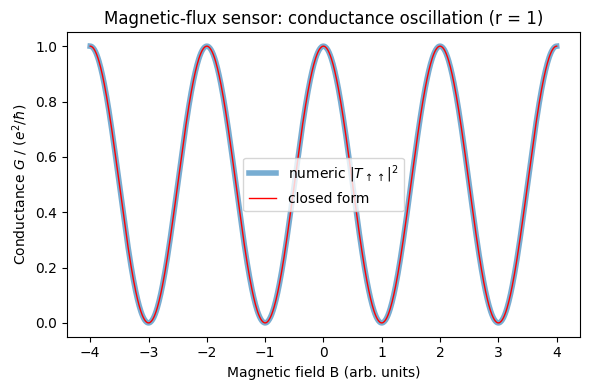

In [29]:
fig, ax = plt.subplots(figsize=(6, 4))
r = 1.0
vals = np.linspace(-4, 4, 800)
G_num = np.array([conductance_ferro(B, r) for B in vals])
G_ana = conductance_ferro_closed(vals, r)
ax.plot(vals, G_num, lw=4, alpha=0.6, label=r"numeric $|T_{\uparrow\uparrow}|^2$")
ax.plot(vals, G_ana, lw=1, color="red", label="closed form")
ax.set_xlabel("Magnetic field B (arb. units)")
ax.set_ylabel(r"Conductance $G$ / ($e^2/\hbar$)")
ax.set_title("Magnetic-flux sensor: conductance oscillation (r = 1)")
ax.legend()
fig.tight_layout()
plt.show()

In [34]:
# spintronics gate 
def transfer_probabilities_normal(B, r, p=0.0):
    T = T_matrix(B, r, np.pi / 2, p)                # full matrix needed
    return {
        "T_up_up": np.abs(T[0, 0])**2,
        "T_down_up": np.abs(T[1, 0])**2,
        "T_up_down": np.abs(T[0, 1])**2,
        "T_down_down": np.abs(T[1, 1])**2,
    }

def switching_quantum(r):
    return hbar/ q*(r**2)
    
def is_identity_or_not(B,r):
    b = switching_quantum(r)
    n = B/b
    n_round = round(n)
    result = "even -> identity lead" if n_round%2 ==0 else " odd -> NOT-gate"
    return n , result



In [35]:
r=1.0
b=switching_quantum(r)
print(f"n | B= n*b | |T_up,up|^2  | |T_down,down|^2 | interpretation " )
for n in range (5):
    B=n*b
    probs = transfer_probabilities_normal(B,r)
    up_up = probs["T_up_up"]
    down_up = probs["T_down_up"]
    res = is_identity_or_not(B,r)
    print(f" {n} | {B:8.4f}  |   {up_up:6.4f}   |   {down_up:6.4f}    | {res}")

n | B= n*b | |T_up,up|^2  | |T_down,down|^2 | interpretation 
 0 |   0.0000  |   1.0000   |   0.0000    | (0.0, 'even -> identity lead')
 1 |   1.0000  |   0.0000   |   1.0000    | (1.0, ' odd -> NOT-gate')
 2 |   2.0000  |   1.0000   |   0.0000    | (2.0, 'even -> identity lead')
 3 |   3.0000  |   0.0000   |   1.0000    | (3.0, ' odd -> NOT-gate')
 4 |   4.0000  |   1.0000   |   0.0000    | (4.0, 'even -> identity lead')


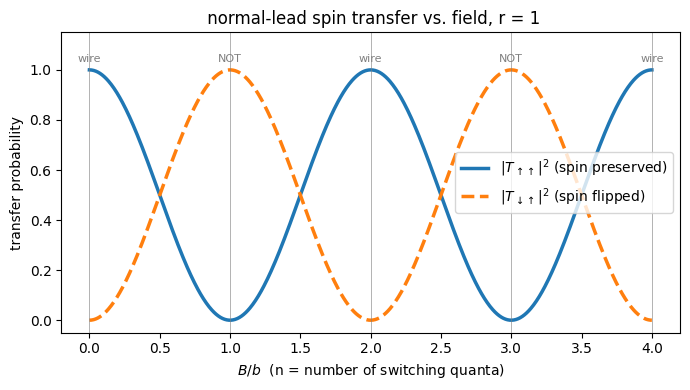

In [58]:
r = 1.0
b = switching_quantum(r)
n_vals = np.linspace(0, 4, 800)
B_vals = n_vals * b
P_up_up = np.array([transfer_probabilities_normal(B, r)["T_up_up"] for B in B_vals])
P_down_up = np.array([transfer_probabilities_normal(B, r)["T_down_up"] for B in B_vals])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n_vals, P_up_up, lw=2.5, label=r"$|T_{\uparrow\uparrow}|^2$ (spin preserved)")
ax.plot(n_vals, P_down_up, lw=2.5, ls="--", label=r"$|T_{\downarrow\uparrow}|^2$ (spin flipped)")
for n in range(5):
    ax.axvline(n, color="grey", lw=0.7, alpha=0.6)
    ax.annotate("NOT" if n % 2 else "wire", (n, 1.03), ha="center", fontsize=8, color="grey")
ax.set_xlabel(r"$B / b$  (n = number of switching quanta)")
ax.set_ylabel("transfer probability")
ax.set_ylim(-0.05, 1.15)
ax.set_title(" normal-lead spin transfer vs. field, r = 1")
ax.legend(loc="center right")
fig.tight_layout()
plt.show()

In [55]:
# three device
def total_transfer_matrix(r1, B1, r2, B2, r3, B3, p=0.0):
    T1 = T_matrix(B1, r1, phi=0.0, p=p)
    T2 = T_matrix(B2, r2, phi=np.pi/2, p=p)
    T3 = T_matrix(B3, r3, phi=0.0, p=p)
    return T3 @ T2 @ T1

def alpha_beta(r1,r2,r3,B1,B2,B3, p=0.0):
    alpha = -p * (r1 + r2+ r3) *np.pi/hbar
    beta1 = -q*B1*r1**2 *np.pi / hbar
    beta2 = -q*B2*r2**2*np.pi/ hbar
    beta3 = -q*B3*r3**2*np.pi/ hbar

    diag1 = np.diag([np.exp(1j*beta1/2), np.exp(-1j*beta1/2)])
    diag3 = np.diag([np.exp(1j*beta3/2), np.exp(-1j*beta3/2)])
    mid = np.array([[np.cos(beta2/2),np.sin(beta2/2)],
                    [-np.sin(beta2/2),np.cos(beta2/2)]])

    T_matrix_closed = np.exp(1j*alpha)*(diag3@mid@diag1)
    T_numeric = total_transfer_matrix(r1,B1,r2,B2,r3,B3)
    return T_matrix_closed, T_numeric, (alpha, beta1, beta2, beta3)
    

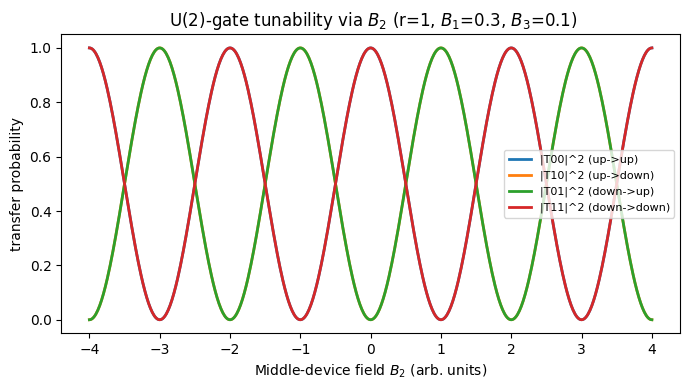

In [61]:
r1 = r2 = r3 = 1.0
B1, B3 = 0.3, 0.1
B2_vals = np.linspace(-4, 4, 600)

elems = {"|T00|^2 (up->up)": [], "|T10|^2 (up->down)": [],
         "|T01|^2 (down->up)": [], "|T11|^2 (down->down)": []}
for B2 in B2_vals:
    _, T_num, _ = alpha_beta(r1,r2,r3,B1,B2,B3)
    elems["|T00|^2 (up->up)"].append(np.abs(T_num[0, 0])**2)
    elems["|T10|^2 (up->down)"].append(np.abs(T_num[1, 0])**2)
    elems["|T01|^2 (down->up)"].append(np.abs(T_num[0, 1])**2)
    elems["|T11|^2 (down->down)"].append(np.abs(T_num[1, 1])**2)

fig, ax = plt.subplots(figsize=(7, 4))
for label, vals_ in elems.items():
    ax.plot(B2_vals, vals_, lw=2, label=label)
ax.set_xlabel("Middle-device field $B_2$ (arb. units)")
ax.set_ylabel("transfer probability")
ax.set_title(f" U(2)-gate tunability via $B_2$ (r=1, $B_1$={B1}, $B_3$={B3})")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()